# Ordenación por mezcla (merge sort)

Divide y vencerás: parte la lista en dos mitades, ordena cada una recursivamente y las mezcla. Cuesta siempre $O(n \log n)$ y es estable, a cambio de $O(n)$ memoria extra.

## 1. Merge sort

Implementar la mezcla de dos listas ordenadas y el merge sort recursivo.

In [1]:
import random

def mezcla(a, b):
    resultado, i, j = [], 0, 0
    while i < len(a) and j < len(b):
        # <= mantiene estabilidad
        if a[i] <= b[j]:
            resultado.append(a[i])
            i += 1
        else:
            resultado.append(b[j])
            j += 1
    return resultado + a[i:] + b[j:]

def merge_sort(lista):
    if len(lista) <= 1:
        return lista
    medio = len(lista) // 2
    return mezcla(merge_sort(lista[:medio]), merge_sort(lista[medio:]))

for _ in range(200):
    datos = random.choices(range(100), k=random.randint(0, 50))
    assert merge_sort(datos) == sorted(datos)
print(merge_sort([38, 27, 43, 3, 9, 82, 10]))

[3, 9, 10, 27, 38, 43, 82]


## 2. Contar inversiones

Una inversión es un par $(i, j)$ con $i < j$ y $l_i > l_j$; mide lo desordenada que está una lista. Contarlas en $O(n \log n)$ aprovechando la mezcla.

In [2]:
def cuenta_inversiones(lista):
    if len(lista) <= 1:
        return lista, 0
    medio = len(lista) // 2
    a, inv_a = cuenta_inversiones(lista[:medio])
    b, inv_b = cuenta_inversiones(lista[medio:])
    resultado, i, j, inv = [], 0, 0, inv_a + inv_b
    while i < len(a) and j < len(b):
        if a[i] <= b[j]:
            resultado.append(a[i])
            i += 1
        else:
            # b[j] es menor que todos los que quedan en a
            inv += len(a) - i
            resultado.append(b[j])
            j += 1
    return resultado + a[i:] + b[j:], inv

datos = [8, 4, 2, 1]
fuerza_bruta = sum(datos[i] > datos[j] for i in range(len(datos)) for j in range(i + 1, len(datos)))
print(cuenta_inversiones(datos)[1], fuerza_bruta)

6 6


## 3. De abajo arriba y estable

Implementar merge sort sin recursión: empezar con tramos de un elemento y mezclarlos de dos en dos (tramos de 1, 2, 4…) hasta que quede uno. Mostrar la traza, comprobar que con `<=` en la mezcla es estable y que con `<` deja de serlo.

In [3]:
def mezcla_clave(a, b, clave, estable=True):
    resultado, i, j = [], 0, 0
    while i < len(a) and j < len(b):
        # con <, a igualdad gana b y adelanta a elementos que iban antes
        if clave(a[i]) <= clave(b[j]) if estable else clave(a[i]) < clave(b[j]):
            resultado.append(a[i])
            i += 1
        else:
            resultado.append(b[j])
            j += 1
    return resultado + a[i:] + b[j:]

def merge_sort_abajo_arriba(lista, clave=lambda x: x, estable=True, traza=False):
    tramos = [[x] for x in lista]
    while len(tramos) > 1:
        tramos = [mezcla_clave(tramos[i], tramos[i + 1], clave, estable) if i + 1 < len(tramos) else tramos[i]
                  for i in range(0, len(tramos), 2)]
        if traza:
            print(tramos)
    return tramos[0] if tramos else []

def nota(alumno):
    return alumno[1]

merge_sort_abajo_arriba([38, 27, 43, 3, 9, 82, 10], traza=True)

alumnos = [("Ana", 7), ("Luis", 5), ("Eva", 7), ("Pau", 10), ("Iker", 5)]
print("Con <=:", merge_sort_abajo_arriba(alumnos, nota))
print("Con < :", merge_sort_abajo_arriba(alumnos, nota, estable=False))
assert merge_sort_abajo_arriba(alumnos, nota, estable=False) != sorted(alumnos, key=nota)

random.seed(3)
for _ in range(300):
    datos = [(random.randint(0, 5), i) for i in range(random.randint(0, 40))]
    assert merge_sort_abajo_arriba(datos, lambda r: r[0]) == sorted(datos, key=lambda r: r[0])

[[27, 38], [3, 43], [9, 82], [10]]
[[3, 27, 38, 43], [9, 10, 82]]
[[3, 9, 10, 27, 38, 43, 82]]
Con <=: [('Luis', 5), ('Iker', 5), ('Ana', 7), ('Eva', 7), ('Pau', 10)]
Con < : [('Iker', 5), ('Luis', 5), ('Eva', 7), ('Ana', 7), ('Pau', 10)]


## 4. Comparaciones: mejor y peor caso

Contar las comparaciones de merge sort. Con $n = 2^k$, una lista ordenada (o inversa) necesita $\frac{n}{2}\log_2 n$, porque cada mezcla agota una mitad sin tocar la otra, y el peor caso, que obliga a alternar hasta el final de cada mezcla, $n \log_2 n - n + 1$. Construir el peor caso repartiendo recursivamente los elementos de posiciones pares a la izquierda y los de impares a la derecha, y dibujar las comparaciones por elemento.

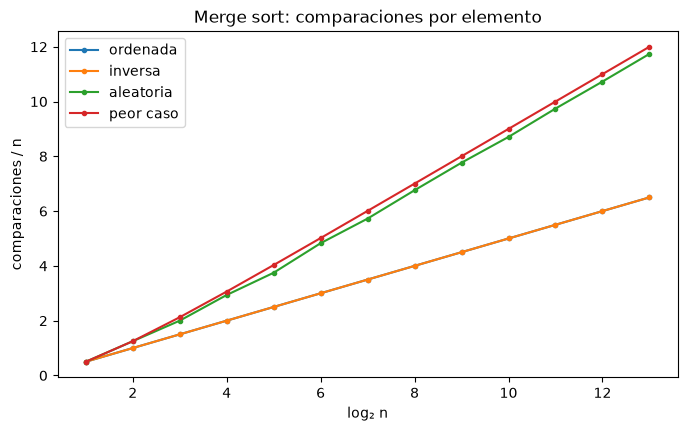

Peor caso con n = 8: [0, 4, 2, 6, 1, 5, 3, 7]


In [4]:
import matplotlib.pyplot as plt

def merge_sort_contando(lista):
    if len(lista) <= 1:
        return lista, 0
    medio = len(lista) // 2
    a, ca = merge_sort_contando(lista[:medio])
    b, cb = merge_sort_contando(lista[medio:])
    resultado, i, j, c = [], 0, 0, ca + cb
    while i < len(a) and j < len(b):
        c += 1
        if a[i] <= b[j]:
            resultado.append(a[i])
            i += 1
        else:
            resultado.append(b[j])
            j += 1
    return resultado + a[i:] + b[j:], c

def peor_caso(ordenada):
    if len(ordenada) <= 1:
        return ordenada
    return peor_caso(ordenada[::2]) + peor_caso(ordenada[1::2])

random.seed(4)
exponentes = range(1, 14)
casos = {
    "ordenada": lambda n: list(range(n)),
    "inversa": lambda n: list(range(n, 0, -1)),
    "aleatoria": lambda n: random.sample(range(n), n),
    "peor caso": lambda n: peor_caso(list(range(n))),
}
fig, ax = plt.subplots(figsize=(8, 4.5))
for nombre, genera in casos.items():
    por_elemento = []
    for k in exponentes:
        n = 2**k
        l, c = merge_sort_contando(genera(n))
        assert l == list(range(n)) or l == list(range(1, n + 1))
        if nombre in ("ordenada", "inversa"):
            assert c == n // 2 * k
        if nombre == "peor caso":
            assert c == n * k - n + 1
        por_elemento.append(c / n)
    ax.plot(exponentes, por_elemento, marker=".", label=nombre)
ax.set(xlabel="log₂ n", ylabel="comparaciones / n", title="Merge sort: comparaciones por elemento")
ax.legend()
plt.show()
print("Peor caso con n = 8:", peor_caso(list(range(8))))